# Q6: no data given? make the table yourself: `make_data()`
The teacher only gives the requirement / the exercise, so we build the data table, then use `auto_prepare()` (Q5) as usual.

3 ways, all in ONE function:
| teacher gives | use |
|---|---|
| a small table (on the board / in the sheet) | `make_data(text="""...paste...""")` |
| a story: columns + ranges + a rule / formula | `make_data(cols={...}, target={...}, n=200)` |
| "the data has missing values, clean it" | add `missing=0.1` |

```python
df = make_data(cols={"size": (30, 200), "rooms": (1, 5, "int"), "city": ["bkk", "cnx"]},
               target={"price": "20000*size + 300000*rooms + 500000*(city=='bkk')"},
               n=300, noise=0.1, save="house.csv")
d = auto_prepare(df, target="price")
```
**In the exam:** copy cell 1 (make_data) and cell 2 (auto_prepare) into your notebook.

## 1. make_data (copy this cell)

In [1]:
import io
import re
import numpy as np
import pandas as pd

def make_data(cols=None, target=None, n=200, noise=0.0, missing=0.0, text=None, save=None, seed=42, show=True):
    """
    ONE function: build the data table yourself.
      text    : paste a table: comma / tab (Excel copy) / ; / spaces / | markdown / JSON
                no header row -> columns x1, x2, ..., y (last column)
                empty cell in a space table -> write NA or ?
      cols    : {"name": spec}  spec can be
                  (lo, hi)            -> random float in [lo, hi]
                  (lo, hi, "int")     -> random int in [lo, hi]
                  ("normal", mean, sd)-> bell-shaped numbers
                  ["a", "b", "c"]     -> random category
                  "formula"           -> made from earlier columns, e.g. "size * 2"
      target  : {"y": "formula"}  e.g. {"price": "20000*size + 5000"}
                a True/False formula ("score > 60") -> class 0/1
      noise   : regression = noise * std(y) added; classification = share of labels flipped
      missing : share of feature cells set to NaN (to practise cleaning)
      save    : "my_data.csv" or ".xlsx" to save it
    returns the DataFrame
    """
    rng = np.random.default_rng(seed)

    # ---------- A. pasted table ----------
    if text is not None:
        t = text.strip()
        if t[0] in "[{":
            df = pd.read_json(io.StringIO(t))
        else:
            lines = [l.strip().strip("|") for l in t.splitlines()]
            lines = [l for l in lines if l and not set(l) <= set("-|: +")]
            if any("|" in l for l in lines):
                lines = [",".join(c.strip() for c in l.split("|")) for l in lines]
            elif not any(s in lines[0] for s in [",", "\t", ";"]):
                gap = r"\s{2,}" if any(re.search(r"\S\s{2,}\S", l) for l in lines) else r"\s+"
                lines = [",".join(re.split(gap, l)) for l in lines]
            first = re.split(r"[,;\t]", lines[0])
            numeric = all(re.fullmatch(r"-?[\d.]+", v.strip()) for v in first)
            df = pd.read_csv(io.StringIO("\n".join(lines)), sep=None, engine="python", header=None if numeric else "infer")
            if numeric:
                df.columns = [f"x{i+1}" for i in range(df.shape[1] - 1)] + ["y"]
        df.columns = [str(c).strip() for c in df.columns]

    # ---------- B. generate from the requirement ----------
    else:
        df = pd.DataFrame(index=range(n))
        for name, s in (cols or {}).items():
            if isinstance(s, str):
                df[name] = eval(s, {"np": np}, {c: df[c] for c in df.columns})
            elif isinstance(s, list):
                df[name] = rng.choice(s, n)
            elif s[0] == "normal":
                df[name] = rng.normal(s[1], s[2], n).round(2)
            elif len(s) == 3 and s[2] == "int":
                df[name] = rng.integers(s[0], s[1] + 1, n)
            else:
                df[name] = rng.uniform(s[0], s[1], n).round(2)

    # ---------- C. target from a formula ----------
    for name, f in (target or {}).items():
        y = eval(f, {"np": np}, {c: df[c] for c in df.columns})
        y = pd.Series(y, index=df.index)
        if y.dtype == bool:
            y = y.astype(int)
            flip = rng.random(len(y)) < noise
            y[flip] = 1 - y[flip]
        else:
            y = (y + rng.normal(0, noise * y.std() if noise else 0, len(y))).round(2)
        df[name] = y

    # ---------- D. holes to practise cleaning ----------
    if missing:
        feats = [c for c in df.columns if c not in (target or {})]
        for c in feats:
            df.loc[rng.random(len(df)) < missing, c] = np.nan

    if save:
        df.to_excel(save, index=False) if save.endswith((".xlsx", ".xls")) else df.to_csv(save, index=False)
    if show:
        print("shape", df.shape, f"| saved to {save}" if save else "")
        for name in (target or {}):
            y = df[name]
            print(f"target {name}:", "class counts " + str(y.value_counts().to_dict()) if y.nunique() <= 10
                  else f"mean {y.mean():.2f}  min {y.min():.2f}  max {y.max():.2f}")
        display(df.head())
    return df

## 2. auto_prepare from Q5 (same function, copy this too)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def auto_prepare(data, target, cols=None, test_size=0.2, max_degree=6, seed=42, show=True):
    """
    ONE function: load any file -> clean -> split -> find the best poly degree.
      data   : file path (csv, txt, tsv, xlsx, json, parquet, zip) or a DataFrame
      target : y column name
      cols   : x columns to use (None = every column after cleaning)
      max_degree : 0 = skip the degree search (classification)
    returns a dict: x_train, x_test, y_train, y_test, cols, degree, xp_train, xp_test, df
      xp_train / xp_test = x, x^2 ... x^degree (scaled), ready for linear()
    """
    say = print if show else (lambda *a: None)

    # ---------- 1. LOAD ----------
    if isinstance(data, pd.DataFrame):
        df = data.copy()
    else:
        p = str(data).lower()
        if p.endswith((".xlsx", ".xls")):
            df = pd.read_excel(data)
        elif p.endswith(".json"):
            try:
                df = pd.read_json(data)
            except ValueError:
                df = pd.read_json(data, lines=True)
        elif p.endswith(".parquet"):
            df = pd.read_parquet(data)
        else:
            for enc in ["utf-8-sig", "cp874", "latin-1"]:
                try:
                    df = pd.read_csv(data, sep=None, engine="python", encoding=enc)
                    break
                except UnicodeDecodeError:
                    pass
            if all(str(c).replace(".", "").replace("-", "").isdigit() for c in df.columns):
                df = pd.read_csv(data, sep=None, engine="python", header=None, encoding=enc)
                df.columns = [f"col{i}" for i in range(df.shape[1])]
                say("no header -> columns named col0, col1 ...")
    say(f"1 load    : {df.shape[0]} rows x {df.shape[1]} cols")

    # ---------- 2. CLEAN ----------
    df.columns = [str(c).strip() for c in df.columns]
    df = df.replace(["?", "", " ", "NA", "N/A", "na", "n/a", "null", "NULL", "None", "-", "--", "missing", -999, -9999], np.nan)
    for c in df.select_dtypes(exclude="number").columns:
        t = df[c].astype(str).str.strip()
        df[c] = df[c].where(df[c].isna(), t if c == target else t.str.lower())
    n = df.duplicated().sum()
    df = df.drop_duplicates()
    say(f"2 clean   : '?', 'NA', -999 ... -> missing | {n} duplicate rows dropped")
    for c in df.select_dtypes(exclude="number").columns:
        num = pd.to_numeric(df[c].astype(str).str.replace(r"[,\s$฿€£%]", "", regex=True), errors="coerce")
        if df[c].notna().sum() and num.notna().sum() >= 0.9 * df[c].notna().sum():
            df[c] = num
            say(f"            {c}: text like '1,200' -> number")
    n = df[target].isna().sum()
    df = df[df[target].notna()]
    if n:
        say(f"            {n} rows without {target} dropped (never fill y)")
    for c in df.select_dtypes(exclude="number").columns:
        if c == target:
            continue
        s = df[c].dropna().astype(str).head(200)
        if len(s) and s.str.contains(r"\d{1,4}[-/.]\d{1,2}[-/.]\d{1,4}").mean() > 0.8:
            d = pd.to_datetime(df[c], errors="coerce", dayfirst=True)
            if d.notna().mean() > 0.8:
                df[c + "_year"], df[c + "_month"], df[c + "_day"], df[c + "_weekday"] = d.dt.year, d.dt.month, d.dt.day, d.dt.weekday
                df = df.drop(columns=c)
                say(f"            {c}: date -> year / month / day / weekday")
    rows = len(df)
    for c in list(df.columns):
        if c == target:
            continue
        nun, miss = df[c].nunique(), df[c].isna().mean()
        idname = str(c).lower().endswith(("id", "index", "_no")) or str(c).lower().startswith("unnamed")
        why = ("id column" if idname and nun > 0.9 * rows
               else "only 1 value" if nun <= 1
               else f"{miss:.0%} missing" if miss > 0.5
               else "text, all different (name)" if not pd.api.types.is_numeric_dtype(df[c]) and nun > 0.9 * rows
               else "")
        if why:
            df = df.drop(columns=c)
            say(f"            drop {c} ({why})")
    for c in df.columns:
        if c == target or not df[c].isna().any():
            continue
        if pd.api.types.is_numeric_dtype(df[c]):
            if df[c].isna().mean() >= 0.05:
                df[c + "_missing"] = df[c].isna().astype(int)
            df[c] = df[c].fillna(df[c].median())
            say(f"            {c}: fill missing with median")
        else:
            df[c] = df[c].fillna(df[c].mode()[0])
            say(f"            {c}: fill missing with most common")
    for c in df.select_dtypes(exclude="number").columns:
        if c == target:
            continue
        nun = df[c].nunique()
        if nun == 2:
            a, b = sorted(df[c].unique())
            df[c] = (df[c] == b).astype(int)
            say(f"            {c}: {a}/{b} -> 0/1")
        elif nun <= 10:
            df = pd.concat([df.drop(columns=c), pd.get_dummies(df[c], prefix=c, drop_first=True, dtype=int)], axis=1)
            say(f"            {c}: one-hot ({nun} values)")
        else:
            df[c] = df[c].map(df[c].value_counts(normalize=True))
            say(f"            {c}: frequency ({nun} values)")
    if not pd.api.types.is_numeric_dtype(df[target]):
        codes = {v: i for i, v in enumerate(sorted(df[target].unique()))}
        df[target] = df[target].map(codes)
        say(f"            target {target}: {codes}")
    say(f"            -> {df.shape[0]} rows x {df.shape[1]} cols")

    # ---------- 3. SPLIT ----------
    cols = [c for c in (cols or df.columns) if c != target]
    df = df[cols + [target]].sample(frac=1, random_state=seed)
    x, y = df[cols].values.astype(float), df[target].values.astype(float)
    n = int(len(df) * (1 - test_size))
    x_train, x_test, y_train, y_test = x[:n], x[n:], y[:n], y[n:]
    say(f"3 split   : train {len(y_train)} | test {len(y_test)} | {len(cols)} x columns")
    out = dict(df=df, cols=cols, x_train=x_train, x_test=x_test, y_train=y_train, y_test=y_test, degree=None)
    if not max_degree:
        return out

    # ---------- 4. BEST POLY DEGREE (5-fold CV on train only) ----------
    mu, sd = x_train.mean(0), x_train.std(0) + 1e-9
    poly = lambda a, d: np.column_stack([np.ones(len(a))] + [((a - mu) / sd) ** p for p in range(1, d + 1)])
    fit = lambda A, b: np.linalg.pinv(A.T @ A) @ A.T @ b
    r2 = lambda a, b: 1 - ((a - b) ** 2).sum() / ((a - a.mean()) ** 2).sum()
    folds = np.array_split(np.arange(len(y_train)), 5)
    res = []
    for d in range(1, max_degree + 1):
        P = poly(x_train, d)
        cv = np.mean([r2(y_train[f], P[f] @ fit(np.delete(P, f, 0), np.delete(y_train, f))) for f in folds])
        res.append([d, r2(y_train, P @ fit(P, y_train)), cv])
    res = pd.DataFrame(res, columns=["degree", "train R2", "CV R2"])
    best = int(res.loc[res["CV R2"] >= res["CV R2"].max() - 0.01, "degree"].min())
    say(f"4 degree  : best = {best} (smallest degree within 0.01 of the top CV R2)")
    if show:
        plt.figure(figsize=(6, 3.5))
        plt.plot(res["degree"], res["train R2"], "o-", label="train R2")
        plt.plot(res["degree"], res["CV R2"], "s-", label="CV R2")
        plt.axvline(best, color="r", linestyle="--", label=f"best = {best}")
        plt.xlabel("degree"); plt.ylabel("R2"); plt.title("Poly degree: pick the top of CV R2")
        plt.legend(); plt.grid(alpha=0.3); plt.show()
        print(res.round(4).to_string(index=False))
    out.update(degree=best, degree_table=res,
               xp_train=poly(x_train, best)[:, 1:], xp_test=poly(x_test, best)[:, 1:])
    return out

## 3. Way 1: the teacher gives a small table → paste it
Any format works: commas, tabs, spaces, or a `|` table.

In [3]:
df = make_data(text="""
| hours | sleep | score |
|-------|-------|-------|
| 1     | 5     | 52    |
| 2     | 6     | 58    |
| 3     | 7     | 65    |
| 4     | 6     | 68    |
| 5     | 8     | 77    |
| 6     | 7     | 80    |
| 7     | 8     | 88    |
| 8     | 6     | 89    |
""")
# same thing by hand:  df = pd.DataFrame({"hours": [1, 2, 3], "score": [52, 58, 65]})

shape (8, 3) 


,hours,sleep,score
0,1,5,52
1,2,6,58
2,3,7,65
3,4,6,68
4,5,8,77


## 4. Way 2: the teacher gives a story → regression (Q1)
*"House price: size 30-200 m², 1-5 rooms, city bkk/cnx/hkt. Price = 20,000 per m² + 300,000 per room, Bangkok +500,000. Make 300 houses, then predict the price."*

In [4]:
df = make_data(cols={"size": (30, 200), "rooms": (1, 5, "int"), "city": ["bkk", "cnx", "hkt"]},
               target={"price": "20000*size + 300000*rooms + 500000*(city=='bkk')"},
               n=300, noise=0.1, save="house.csv")
d = auto_prepare(df, target="price", show=False)

def linear(x_train, y_train, x_test):
    X = np.c_[np.ones(len(x_train)), x_train]
    w = np.linalg.pinv(X.T @ X) @ X.T @ y_train
    return np.c_[np.ones(len(x_test)), x_test] @ w

def r2(y, p):
    return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()

p = linear(d["x_train"], d["y_train"], d["x_test"])
print("cols", d["cols"], "| best degree", d["degree"], "| Multi test R2 =", round(r2(d["y_test"], p), 4))

shape (300, 4) | saved to house.csv
target price: mean 3319658.51  min 975296.01  max 5457588.54


,size,rooms,city,price
0,161.57,4,bkk,5066690.40
1,104.61,4,bkk,3764824.57
2,175.96,4,bkk,5258602.13
3,148.55,1,hkt,3009740.09
4,46.01,5,cnx,2294840.22


cols ['size', 'rooms', 'city_cnx', 'city_hkt'] | best degree 1 | Multi test R2 = 0.9858


## 5. A curve: the teacher gives a formula → auto_prepare finds the degree
*"y = 2x² − 3x + 5, x from −5 to 5, 150 points, add noise."* We know the answer is 2, so this checks the degree finder.

shape (150, 2) 
target y: mean 20.33  min 0.68  max 67.98


,x,y
0,2.74,14.56
1,-0.61,7.98
2,3.59,19.60
3,1.97,4.17
4,-4.06,45.81


1 load    : 150 rows x 2 cols
2 clean   : '?', 'NA', -999 ... -> missing | 0 duplicate rows dropped
            -> 150 rows x 2 cols
3 split   : train 120 | test 30 | 1 x columns
4 degree  : best = 2 (smallest degree within 0.01 of the top CV R2)


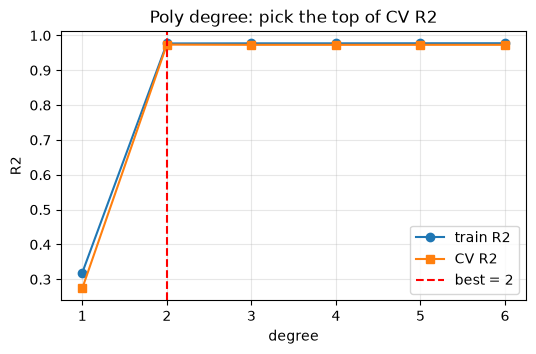

 degree  train R2  CV R2
      1    0.3190 0.2743
      2    0.9770 0.9737
      3    0.9773 0.9731
      4    0.9773 0.9731
      5    0.9775 0.9731
      6    0.9776 0.9731
found degree 2 (true = 2) | Poly test R2 = 0.9813


In [5]:
df = make_data(cols={"x": (-5, 5)}, target={"y": "2*x**2 - 3*x + 5"}, n=150, noise=0.15)
d = auto_prepare(df, target="y")
p = linear(d["xp_train"], d["y_train"], d["xp_test"])
print(f"found degree {d['degree']} (true = 2) | Poly test R2 = {r2(d['y_test'], p):.4f}")

## 6. A rule → classification (Q2)
*"Students pass if 5×hours + 3×sleep > 55. hours 0-10, sleep 4-9, 5% of labels are wrong. Predict pass/fail."*
A True/False formula makes a 0/1 class. `noise=0.05` flips 5% of the labels.

In [6]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"; warnings.filterwarnings("ignore")
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score

df = make_data(cols={"hours": (0, 10), "sleep": (4, 9), "club": ["yes", "no"]},
               target={"passed": "5*hours + 3*sleep > 55"}, n=400, noise=0.05)
d = auto_prepare(df, target="passed", max_degree=0, show=False)
for m in [LogisticRegression(max_iter=1000), HistGradientBoostingClassifier(random_state=42)]:
    m.fit(d["x_train"], d["y_train"])
    print(type(m).__name__, "accuracy", round(accuracy_score(d["y_test"], m.predict(d["x_test"])), 4))

shape (400, 4) 
target passed: class counts {0: 284, 1: 116}


,hours,sleep,club,passed
0,7.74,5.51,yes,1
1,4.39,8.59,no,0
2,8.59,7.91,no,1
3,6.97,4.55,yes,0
4,0.94,8.99,yes,0


LogisticRegression accuracy 0.95
HistGradientBoostingClassifier accuracy 0.9625


## 7. Q2 style: class first, then regression with the predicted class
*"Loan: income 15k-150k, age 20-60. Approved if income > 40k and age < 55. Amount = 5×income (+50k if age < 35). Predict approved, then the amount."*
A formula can use an earlier column (`"approved"` is used inside `amount`).

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = make_data(cols={"income": (15000, 150000), "age": (20, 60, "int"),
                     "approved": "((income > 40000) & (age < 55)).astype(int)"},
               target={"amount": "approved * (5*income + 50000*(age < 35))"}, n=500, noise=0.05, show=False)
tr, te = train_test_split(df.index, test_size=0.2, random_state=42)

# step 1: class
X = df[["income", "age"]].values
clf = HistGradientBoostingClassifier(random_state=42).fit(X[tr], df.loc[tr, "approved"])
df["approved_pred"] = clf.predict(X)
print("class accuracy", round(accuracy_score(df.loc[te, "approved"], df.loc[te, "approved_pred"]), 4))

# step 2: regression that uses the predicted class
X2 = df[["income", "age", "approved_pred"]].values
reg = HistGradientBoostingRegressor(random_state=42).fit(X2[tr], df.loc[tr, "amount"])
print("amount R2", round(r2_score(df.loc[te, "amount"], reg.predict(X2[te])), 4))

class accuracy 0.99
amount R2 0.9861


## 8. "Make dirty data, then clean it"
`missing=0.1` punches 10% holes in every feature; `auto_prepare` fills them.

holes before: {'size': 20, 'city': 25, 'price': 0}
1 load    : 200 rows x 3 cols
2 clean   : '?', 'NA', -999 ... -> missing | 0 duplicate rows dropped
            size: fill missing with median
            city: fill missing with most common
            city: bkk/cnx -> 0/1
            -> 200 rows x 4 cols
3 split   : train 160 | test 40 | 3 x columns
4 degree  : best = 1 (smallest degree within 0.01 of the top CV R2)


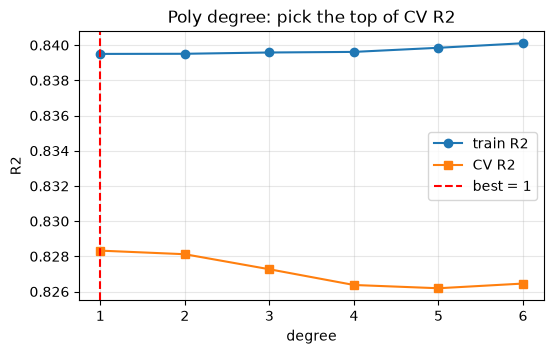

 degree  train R2  CV R2
      1    0.8395 0.8283
      2    0.8395 0.8281
      3    0.8396 0.8273
      4    0.8396 0.8264
      5    0.8398 0.8262
      6    0.8401 0.8265


In [8]:
df = make_data(cols={"size": (30, 200), "city": ["bkk", "cnx"]},
               target={"price": "20000*size + 500000*(city=='bkk')"}, n=200, noise=0.1, missing=0.1, show=False)
print("holes before:", df.isna().sum().to_dict())
d = auto_prepare(df, target="price")

## Spare: sklearn ready-made fake data (when the teacher says "any data")
```python
from sklearn.datasets import make_regression, make_classification, make_blobs
X, y = make_regression(n_samples=200, n_features=3, noise=10, random_state=42)
X, y = make_classification(n_samples=300, n_features=4, n_informative=2, random_state=42)
X, y = make_blobs(n_samples=300, centers=3, random_state=42)          # clustering
df = pd.DataFrame(X, columns=[f"x{i}" for i in range(X.shape[1])]); df["y"] = y
d = auto_prepare(df, target="y")
```